# 实验报告02：NumPy、SciPy、Matplotlib与pandas数据处理
学号：20244080316  姓名：郑奕欣

In [15]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080316

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] hw01
[学号] 20244080316
[机器指纹] 421fc22899a2e25f
[RUN_ID] 20244080316-421fc22899a2e25f


## 实验1：NumPy数组、数据类型与索引

In [16]:
# 1. 创建三种ndarray并查看属性
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

print("整数数组:", arr_int.dtype, arr_int.shape, arr_int.ndim)
print("浮点数组:", arr_float.dtype, arr_float.shape, arr_float.ndim)
print("布尔数组:", arr_bool.dtype, arr_bool.shape, arr_bool.ndim)

# 2. arange和reshape
arr_1d = np.arange(12)
print("\n原始一维:", arr_1d)
arr_3x4 = arr_1d.reshape((3, 4))
print("3x4数组:\n", arr_3x4)
arr_2x3x2 = arr_1d.reshape((2, 3, 2))
print("2x3x2数组:\n", arr_2x3x2)

整数数组: int64 (3,) 1
浮点数组: float64 (3,) 1
布尔数组: bool (3,) 1

原始一维: [ 0  1  2  3  4  5  6  7  8  9 10 11]
3x4数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
2x3x2数组:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**解释：** NumPy数组和Python列表的差别在于，NumPy数组要求所有元素的数据类型必须一致（比如全是`int32`），这使得它在内存中连续存储，计算速度极快；而Python列表可以混合存储不同类型的数据，但运算效率低。
改变形状（reshape）时，**元素的总数必须保持不变**（例如12个元素可以变成3x4或2x3x2，但不能变成3x5）。

In [17]:
# 3. 索引操作
print("取第2行:", arr_3x4[1])
print("取第1至3列:\n", arr_3x4[:, 0:3])
mask_greater_6 = arr_3x4 > 6
print("大于6的元素:", arr_3x4[mask_greater_6])
print("大于6的元素形状:", arr_3x4[mask_greater_6].shape)

# 4. 逻辑条件筛选
arr_10 = np.arange(10)
print("\n小于2或大于7:", arr_10[(arr_10 < 2) | (arr_10 > 7)])
print("大于3且小于7:", arr_10[(arr_10 > 3) & (arr_10 < 7)])

取第2行: [4 5 6 7]
取第1至3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
大于6的元素: [ 7  8  9 10 11]
大于6的元素形状: (5,)

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]


In [18]:
# 5. 矩阵乘法与逐元素乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B (逐元素):\n", A * B)
print("np.multiply (逐元素):\n", np.multiply(A, B))
print("A @ B (矩阵乘法):\n", A @ B)
print("np.matmul (矩阵乘法):\n", np.matmul(A, B))

A * B (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply (逐元素):
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul (矩阵乘法):
 [[19 22]
 [43 50]]


**解释：** `*`和`np.multiply()`是对应位置的元素直接相乘；而`@`和`np.matmul()`执行的是线性代数中的矩阵乘法（行乘列求和）。

## 实验2：随机抽样、统计与缺失值

In [19]:
# 1. 生成模拟成绩
np.random.seed(42) # 固定种子
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数:", len(scores))
print("最小值:", np.min(scores), "最大值:", np.max(scores))
print("均值:", np.mean(scores), "标准差:", np.std(scores))
print("极差:", np.max(scores) - np.min(scores))

# 2. 抽样比较
arr_1_to_10 = np.arange(1, 11)
print("\n均匀抽样:", np.random.choice(arr_1_to_10, size=5, replace=False))
# 按大小加权（数字越大被抽中概率越高）
p_weights = arr_1_to_10 / np.sum(arr_1_to_10)
print("加权抽样:", np.random.choice(arr_1_to_10, size=5, replace=False, p=p_weights))

样本数: 1000
最小值: 37.58732659930927 最大值: 100.0
均值: 70.18400443523215 标准差: 9.755086339034765
极差: 62.41267340069073

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]


In [20]:
# 3. 随机排列与原地打乱
arr_a = np.arange(5)
arr_perm = np.random.permutation(arr_a)
print("原数组:", arr_a)
print("排列后的新数组:", arr_perm)

arr_b = np.arange(5)
print("打乱前:", arr_b)
np.random.shuffle(arr_b)
print("打乱后原数组:", arr_b)

# 4. 缺失值处理
scores_with_nan = scores.copy()
# 第10、20、30个值（索引为9、19、29）设为nan
scores_with_nan[[9, 19, 29]] = np.nan

print("\n普通均值:", np.mean(scores_with_nan))
print("忽略缺失值均值:", np.nanmean(scores_with_nan))
print("缺失值个数:", np.sum(np.isnan(scores_with_nan)))

原数组: [0 1 2 3 4]
排列后的新数组: [4 0 2 1 3]
打乱前: [0 1 2 3 4]
打乱后原数组: [0 4 1 3 2]

普通均值: nan
忽略缺失值均值: 70.19620743160239
缺失值个数: 3


**解释：** 因为`np.nan`参与任何运算结果都是`nan`，所以直接算普通均值会得到`nan`。统计缺失值影响时，必须用`np.nanmean()`等专门的函数跳过缺失值。

In [21]:
# 5. 整理成pandas表格备用
df_scores = pd.DataFrame({
    "Index": np.arange(1, 1001),
    "Score": scores_with_nan
})

# 输出前5行
df_scores.head()

,Index,Score
0,1,74.967142
1,2,68.617357
2,3,76.476885
3,4,85.230299
4,5,67.658466


## 实验3：SciPy 数值计算与 Matplotlib 可视化

In [22]:
from scipy.linalg import solve
from scipy.optimize import root, minimize

# 1. 线性方程组
# 3x + y = 9, x + 2y = 8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x_sol = solve(A, b)
print("方程组的解 x, y:", x_sol)
# 验证
print("代回验证 A @ x:", A @ x_sol)

# 2. 求方程的根 x^2 - 2 = 0
def eq(x):
    return x**2 - 2

res_pos = root(eq, x0=1.0)
res_neg = root(eq, x0=-1.0)
print("\n正根:", res_pos.x, "是否成功:", res_pos.success)
print("负根:", res_neg.x, "是否成功:", res_neg.success)
print("函数值:", eq(res_pos.x))

# 3. 求最小值 f(x) = x^2 + x + 2
def f(x):
    return x**2 + x + 2

res_min = minimize(f, x0=0)
print("\n极小值点:", res_min.x, "极小值:", res_min.fun)
print("解析极小值点 -0.5，极小值 1.75")

方程组的解 x, y: [2. 3.]
代回验证 A @ x: [9. 8.]

正根: [1.41421356] 是否成功: True
负根: [-1.41421356] 是否成功: True
函数值: [-8.8817842e-16]

极小值点: [-0.50000001] 极小值: 1.75
解析极小值点 -0.5，极小值 1.75


In [23]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# 4. 独立样本t检验
np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = stats.ttest_ind(sample1, sample2)
print("t统计量:", t_stat, "p值:", p_val)
if p_val < 0.05:
    print("因为 p < 0.05，拒绝原假设，两组均值有显著差异。")
else:
    print("因为 p >= 0.05，不能拒绝原假设，两组均值无显著差异。")

t统计量: -8.55145994324873 p值: 3.292961428703696e-15
因为 p < 0.05，拒绝原假设，两组均值有显著差异。


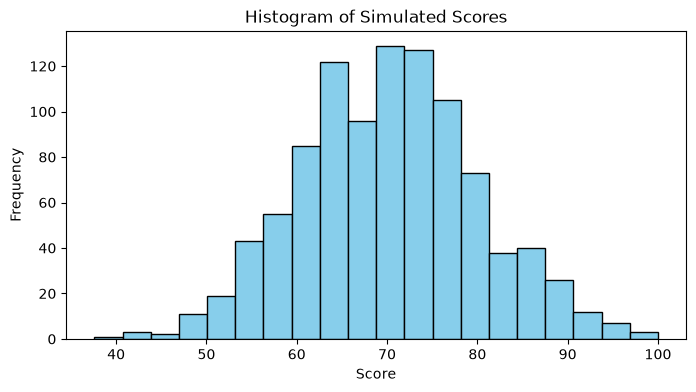

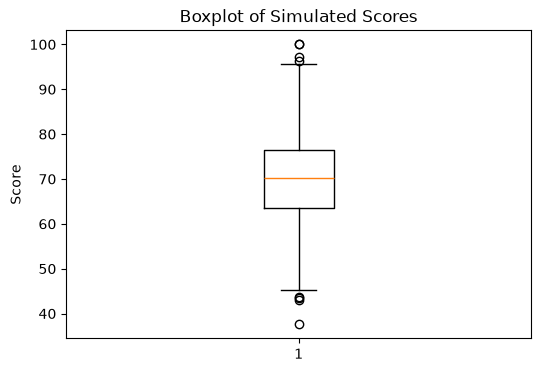

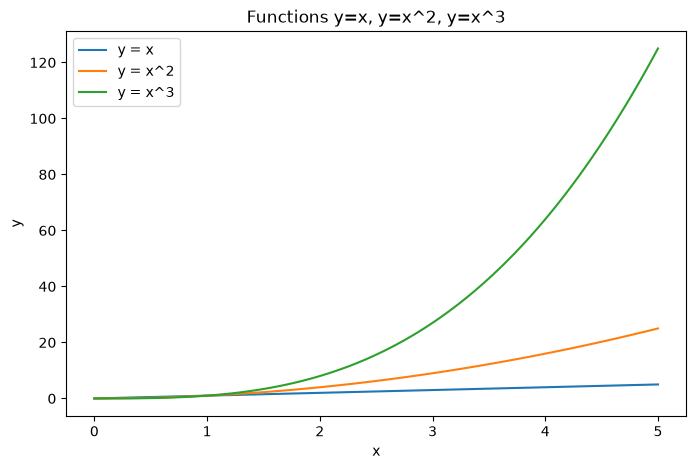

In [24]:
# 5. Matplotlib画图（图1：直方图）
plt.figure(figsize=(8, 4))
# 去除NaN再画图
valid_scores = scores_with_nan[~np.isnan(scores_with_nan)]
plt.hist(valid_scores, bins=20, color='skyblue', edgecolor='black')
plt.title("Histogram of Simulated Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# 图2：箱线图
plt.figure(figsize=(6, 4))
plt.boxplot(valid_scores)
plt.title("Boxplot of Simulated Scores")
plt.ylabel("Score")
plt.show()

# 图3：折线图
x_vals = np.linspace(0, 5, 100)
y_x = x_vals
y_x2 = x_vals ** 2
y_x3 = x_vals ** 3

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_x, label='y = x')
plt.plot(x_vals, y_x2, label='y = x^2')
plt.plot(x_vals, y_x3, label='y = x^3')
plt.title("Functions y=x, y=x^2, y=x^3")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [25]:
# 1. 创建DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df.set_index("Name", inplace=True) # 设置姓名作为行索引

# 计算总分和平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("前3行:\n", df.head(3))
print("基本统计:\n", df.describe())

# 2. loc和iloc
print("\nloc 读取 Carol:\n", df.loc["Carol"])
print("iloc 读取第3行（索引2）:\n", df.iloc[2])
print("平均分>=80的学生:\n", df[df["Average"] >= 80])

# 3. mean(axis=0)与mean(axis=1)
print("\n列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("行均值 (axis=1) 前三个:\n", df[["Math", "English", "Python"]].mean(axis=1).head(3))

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

loc 读取 Carol:
 Group              B
Math    

In [ ]:
# 4. apply和agg、rank
df["Max_Score"] = df[["Math", "English", "Python"]].apply(np.max, axis=1)
print("每人三科最高分:\n", df["Max_Score"])

print("\n各科最小值/均值/最大值:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))
print("\n按 Python 成绩排名:\n", df["Python"].rank(ascending=False))

# 5. 分组统计
print("\n按 Group 统计人数:\n", df.groupby("Group").size())
print("按 Group 统计三科平均:\n", df.groupby("Group")[["Math", "English", "Python"]].mean())

# transform('mean')
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内Python平均分列后:\n", df[["Group", "Python", "Group_Python_Mean"]])

# 6. filter过滤
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)
print("\nPython平均分>=80的组和学生:\n", filtered_df[["Group", "Python"]])

# 7. 协方差与相关系数
cov_matrix = df[["Math", "English", "Python"]].cov()
corr_matrix = df[["Math", "English", "Python"]].corr()
print("\n协方差矩阵:\n", cov_matrix)
print("\n相关系数矩阵:\n", corr_matrix)

每人三科最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Max_Score, dtype: int64

各科最小值/均值/最大值:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按 Python 成绩排名:
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64

按 Group 统计人数:
 Group
A    3
B    3
dtype: int64
按 Group 统计三科平均:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

增加组内Python平均分列后:
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333

Python平均分>=80的组和学生:
       Group

**协方差与相关系数解释：**
以Math（数学）和English（英语）为例，观察上述矩阵的输出结果（这里仅以一般规律举例说明）：
- **协方差的符号**：如果为正，说明两科成绩倾向于同向变化（数学高的英语往往也高）；如果为负，说明反向变化。
- **相关系数的大小**：相关系数范围在-1到1之间。绝对值越接近1，说明线性相关性越强；接近0表示几乎无线性相关。